# Accent Gap: analysis notebook
Loads the cached results in `results/` (produced by `src/analyze.py`) and shows every table and chart
used in the README. Nothing here re-runs Whisper. WER = word error rate in %, lower is better.
CIs are 95% bootstrap intervals that resample **speakers**.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 200, "display.width", 250, "display.max_rows", 200)
R = "results/"
def show(name, **kw):
    df = pd.read_csv(R + name, keep_default_na=False, **kw)
    display(df)
    return df

## 1. The data: EdAcc clips and speakers per accent / first language

In [2]:
ov = pd.read_csv(R + "dataset_overview.csv")
ov[ov.value.str.contains("Indian|Hindi|Urdu|Sinhal|US English|British", regex=True)]

,field,split,value,clips,speakers
2,accent,test,Mainstream US English,887,9
4,accent,test,Indian English,631,3
15,accent,test,Southern British English,181,2
24,accent,validation,Southern British English,1190,9
25,accent,validation,Mainstream US English,1096,8
33,accent,validation,Indian English,373,2
55,l1,test,Mainstream US English,395,4
58,l1,test,Hindi,350,1
59,l1,test,Indian English,281,2
61,l1,test,Urdu,274,2


Evaluation set actually used (last 40% of each speaker's conversation, 1-30 s, max 100 clips per speaker):

In [3]:
show("eval_set_summary.csv");

,group,subgroup,speakers,eval_or_dev_clips,eval_minutes,history_clips
0,DEV,Irish English,7,249,26.6,778
1,DEV,Italian,7,168,21.5,513
2,DEV,Kenyan English,2,80,7.1,676
3,DEV,Scottish English,4,131,17.1,265
4,DEV,South African English,2,66,8.4,146
5,DEV,Vietnamese,10,254,32.5,615
6,Jamaican English,Jamaican English,6,204,20.2,448
7,Native US/UK English,UK English,9,341,39.7,729
8,Native US/UK English,US English,6,166,14.4,438
9,Nigerian English,Nigerian English,5,274,30.6,801


## 2. E1: the accent gap (whisper-small, plain)

,system,level,group,name,speakers,clips,ref_words,wer_pct,ci_low_pct,ci_high_pct,mean_speaker_wer_pct,sub_pct,del_pct,ins_pct
0,small_plain,group,Jamaican English,Jamaican English,6,204,3036,37.6,24.4,58.9,39.0,16.8,12.7,8.1
1,small_plain,group,Native US/UK English,Native US/UK English,15,507,9191,23.1,19.2,27.5,21.6,7.5,13.9,1.7
2,small_plain,group,Nigerian English,Nigerian English,5,274,5508,28.1,25.9,30.2,28.2,9.9,16.1,2.0
3,small_plain,group,South Asian English,South Asian English,8,356,5589,20.6,17.1,26.2,22.9,6.2,12.8,1.6
4,small_plain,group,Spanish-accented English,Spanish-accented English,6,287,4569,25.4,23.0,28.4,26.5,9.1,13.3,3.0
5,small_plain,subgroup,South Asian English,Indian English accent,4,265,4078,19.3,16.0,26.7,21.5,5.4,12.1,1.8
6,small_plain,subgroup,South Asian English,Sinhalese L1,2,28,342,18.4,10.1,34.8,22.5,11.7,6.1,0.6
7,small_plain,subgroup,Native US/UK English,UK English,9,341,6281,21.7,18.9,24.6,21.8,8.6,11.3,1.8
8,small_plain,subgroup,Native US/UK English,US English,6,166,2910,26.1,14.7,34.8,21.2,5.1,19.5,1.5
9,small_plain,subgroup,South Asian English,Urdu L1,2,63,1169,25.9,25.4,27.0,26.2,7.4,17.2,1.4


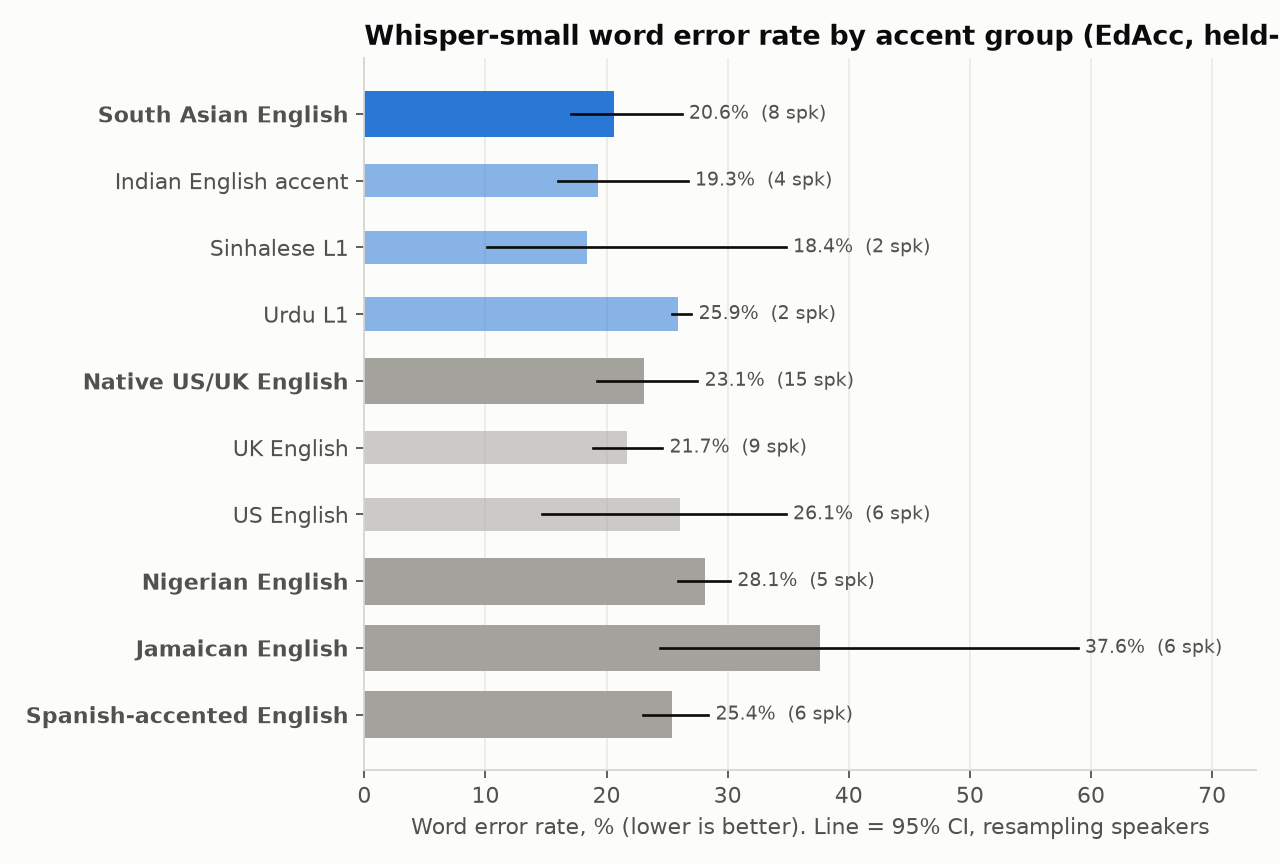

In [4]:
show("wer_by_group.csv"); display(Image(R + "wer_by_group.png"))

How many times higher is each group's WER than native US/UK speakers' (with 95% CI)?

In [5]:
show("accent_gap.csv");

,system,group,group_wer_pct,native_wer_pct,ratio_vs_native,ratio_ci_low,ratio_ci_high
0,base_plain,South Asian English,25.7,29.0,0.89,0.73,1.13
1,base_plain,Nigerian English,39.0,29.0,1.34,1.11,1.77
2,base_plain,Jamaican English,52.9,29.0,1.82,1.17,2.87
3,base_plain,Spanish-accented English,41.5,29.0,1.43,1.16,1.71
4,small_plain,South Asian English,20.6,23.1,0.89,0.69,1.20
5,small_plain,Nigerian English,28.1,23.1,1.21,1.01,1.47
6,small_plain,Jamaican English,37.6,23.1,1.63,1.03,2.60
7,small_plain,Spanish-accented English,25.4,23.1,1.10,0.90,1.37
8,medium_plain,South Asian English,18.0,18.7,0.96,0.77,1.30
9,medium_plain,Nigerian English,26.5,18.7,1.42,1.16,1.74


Per-speaker WER (whisper-small, plain). Groups are small, so look at the spread within each group:

In [6]:
spk = pd.read_csv(R + "wer_by_speaker.csv")
spk[spk.system == "small_plain"].sort_values(["group", "wer_pct"])

,system,speaker,group,subgroup,l1,gender,clips,ref_words,wer_pct
113,small_plain,EDACC-C48-B,Jamaican English,Jamaican English,Jamaican English,female,13,413,15.3
114,small_plain,EDACC-C49-A,Jamaican English,Jamaican English,Jamaican English,female,42,781,25.2
116,small_plain,EDACC-C52-A,Jamaican English,Jamaican English,Jamaican English,male,48,706,29.7
112,small_plain,EDACC-C48-A,Jamaican English,Jamaican English,Jamaican English,female,9,230,35.7
115,small_plain,EDACC-C49-B,Jamaican English,Jamaican English,Jamaican English,female,41,420,49.5
117,small_plain,EDACC-C52-B,Jamaican English,Jamaican English,Jamaican English,male,51,486,78.8
92,small_plain,EDACC-C19-B,Native US/UK English,US English,Mainstream US English,female,6,121,3.3
90,small_plain,EDACC-C14-A,Native US/UK English,US English,Mainstream US English,female,35,434,13.4
118,small_plain,EDACC-C63-B,Native US/UK English,US English,Mainstream US English,female,25,390,13.6
109,small_plain,EDACC-C42-B,Native US/UK English,UK English,Southern British English,male,24,510,15.3


## 3. E2: does a bigger model close the gap?

system,base_plain,medium_plain,small_plain
name,,,
Jamaican English,52.9,29.9,37.6
Native US/UK English,29.0,18.7,23.1
Nigerian English,39.0,26.5,28.1
South Asian English,25.7,18.0,20.6
Spanish-accented English,41.5,25.5,25.4


,model,mean_seconds_per_clip
0,whisper-base,0.199
1,whisper-small,0.270
2,whisper-medium,1.140


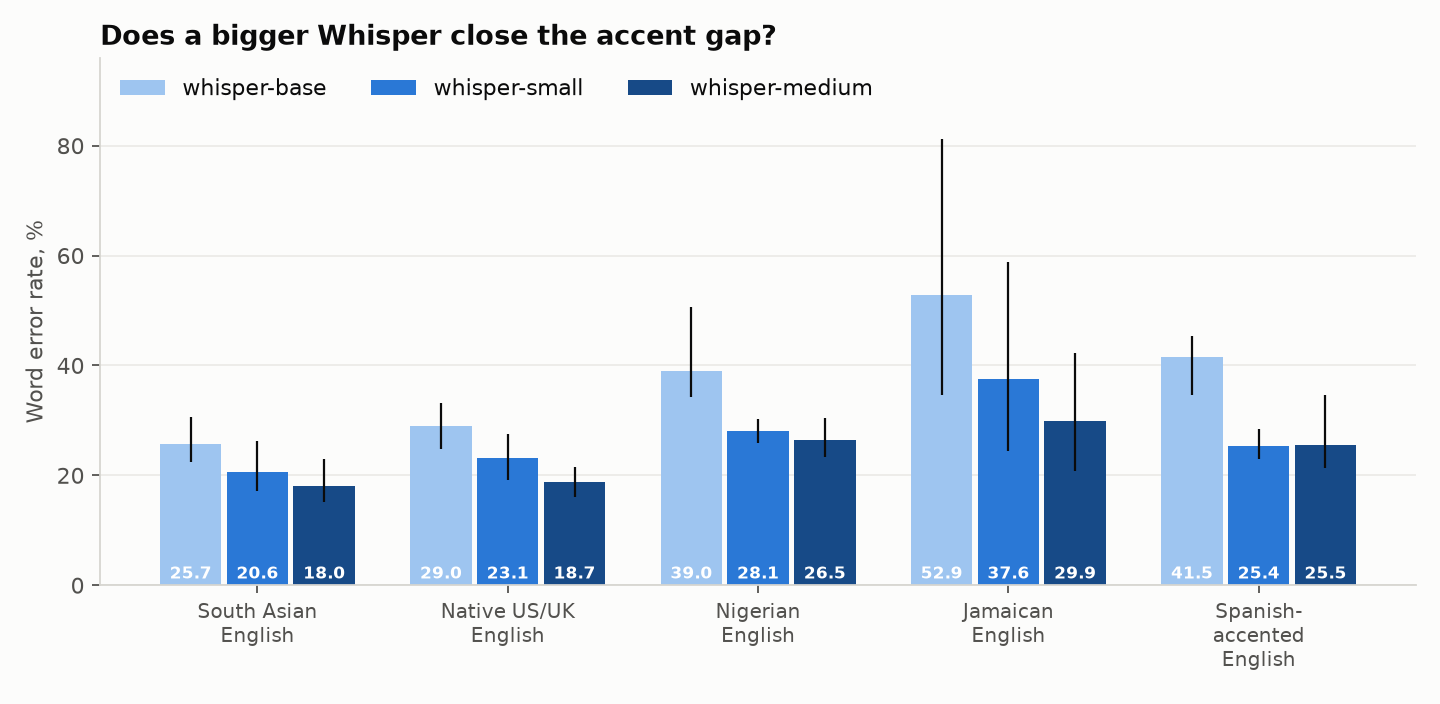

In [7]:
wt = pd.read_csv(R + "wer_by_group_all_systems.csv")
e2 = wt[(wt.level == "group") & wt.system.str.endswith("_plain")]
display(e2.pivot(index="name", columns="system", values="wer_pct"))
show("model_speed.csv")
display(Image(R + "model_size.png"))

## 4. E3: personal mode
For each speaker: word list from the first 60% of their conversation (text only) → Whisper prompt → scored on the last 40%.
`gain_points` = plain WER − prompted WER (positive = personal mode helped). Control = someone else's list.

,model,prompt,group,speakers,clips,plain_wer_pct,prompted_wer_pct,gain_points,gain_ci_low,gain_ci_high,relative_gain_pct,speakers_improved,speakers_worse
0,base,personal_v1,South Asian English,8,356,25.7,31.7,-6.0,-19.8,-0.4,-23.4,2,6
1,base,personal_v1,Native US/UK English,15,507,29.0,38.6,-9.5,-16.7,-4.1,-32.8,3,12
2,base,personal_v1,Nigerian English,5,274,39.0,57.4,-18.4,-21.8,-7.0,-47.2,1,4
3,base,personal_v1,Jamaican English,6,204,52.9,68.5,-15.6,-30.1,-6.9,-29.5,0,6
4,base,personal_v1,Spanish-accented English,6,287,41.5,46.9,-5.4,-19.3,-0.1,-13.1,1,5
5,base,personal_v1,All groups (40 speakers),40,1628,35.0,45.5,-10.6,-15.0,-6.5,-30.2,7,33
6,small,personal,South Asian English,8,356,20.6,19.3,1.3,-1.1,4.6,6.3,5,3
7,small,personal,Native US/UK English,15,507,23.1,21.9,1.2,-1.7,4.5,5.1,7,7
8,small,personal,Nigerian English,5,274,28.1,27.2,0.9,-1.5,2.5,3.1,3,2
9,small,personal,Jamaican English,6,204,37.6,34.6,3.0,-1.7,10.2,8.0,2,4


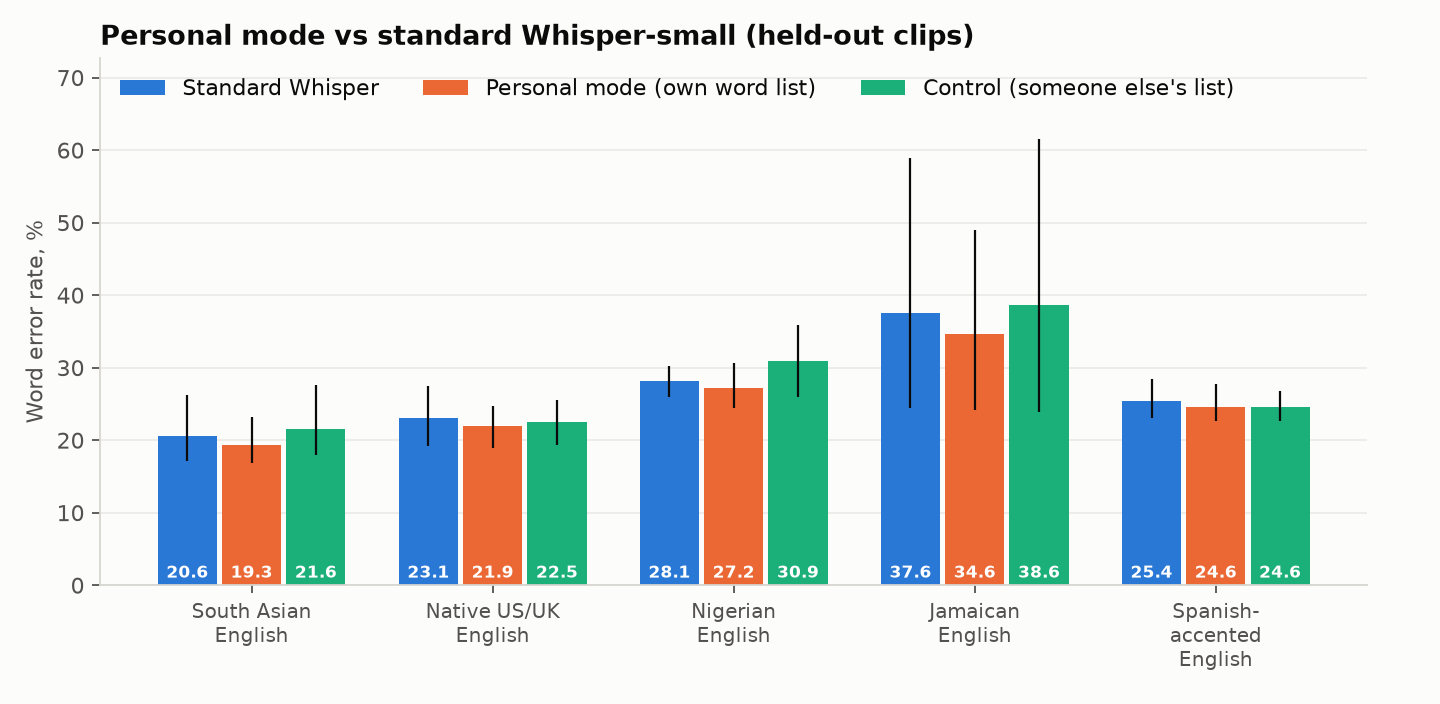

In [8]:
show("personal_mode_by_group.csv"); display(Image(R + "personal_mode.png"))

Does personal mode help South Asian speakers *more* than native speakers? (difference of gains, with CI)

In [9]:
show("personal_mode_gain_comparison.csv");

,model,prompt,gain_south_asian_points,gain_native_points,difference_points,difference_ci_low,difference_ci_high
0,base,personal_v1,-6.0,-9.5,3.5,-11.6,12.8
1,small,personal,1.3,1.2,0.1,-4.0,4.5
2,small,control,-1.0,0.6,-1.6,-4.5,1.2
3,small,personal_v1,-1.8,-3.0,1.2,-8.8,7.8
4,small,control_v1,0.6,-5.0,5.7,0.7,10.7


Per speaker (whisper-small):

In [10]:
ps = pd.read_csv(R + "personal_mode_by_speaker.csv")
ps[ps.model == "small"].pivot_table(index=["group", "speaker"], columns="prompt", values="gain_points")

prompt                                control  control_v1  personal  personal_v1
group                    speaker                                                
Jamaican English         EDACC-C48-A     -0.4         7.8      -1.3          4.8
                         EDACC-C48-B      0.0         1.9      -0.2          0.5
                         EDACC-C49-A      2.9        -5.4       2.9        -12.0
                         EDACC-C49-B     -5.0       -39.5      -2.6        -65.7
                         EDACC-C52-A     -2.0       -42.6      -1.6         -7.9
                         EDACC-C52-B     -3.3       -57.0      19.5        -20.0
Native US/UK English     EDACC-C03-B      0.0         1.2      -0.5          0.5
                         EDACC-C06-A      0.6         0.9      -4.3          1.9
                         EDACC-C06-B      0.5         1.0       5.9          0.2
                         EDACC-C07-A      9.0        -2.7      13.5          6.1
                         EDACC-C11-B      0.0         0.3      -0.7          0.5
                         EDACC-C14-A      0.5         0.2       1.4         -2.3
                         EDACC-C17-B     -0.2       -26.0      -0.3         -1.2
                         EDACC-C19-B      0.0         0.0       0.0         -6.6
                         EDACC-C32-A      3.7        -0.9       4.7          3.3
                         EDACC-C32-B      1.3       -21.2       1.7        -23.2
                         EDACC-C33-A     -5.4        -8.8      -6.2         -8.0
                         EDACC-C41-B     -3.0        -5.4      -4.2         -2.6
                         EDACC-C42-B     -2.2        -3.3      -0.4         -0.6
                         EDACC-C63-B      1.3         0.0       2.3          0.0
                         EDACC-C64-A     -0.3        -0.3       0.8        -14.8
Nigerian English         EDACC-C29-A     -7.8        -5.1      -0.9         -1.0
                         EDACC-C29-B     -0.6         0.5       2.4         -5.6
                         EDACC-C41-A      0.7        -1.5       1.2         -0.9
                         EDACC-C45-A      0.3         0.2       3.5          4.5
                         EDACC-C45-B     -4.0        -0.6      -5.9        -16.4
South Asian English      EDACC-C05-B     -1.5         1.0      -2.4          0.9
                         EDACC-C09-A     -4.1       -11.4      -0.2        -22.1
                         EDACC-C09-B     -4.6         0.8       8.0          4.4
                         EDACC-C10-A      1.7         0.0       2.6          3.5
                         EDACC-C10-B      0.4        -2.6      -0.9         -2.2
                         EDACC-C31-A      3.2         6.3       4.0          5.9
                         EDACC-C31-B      1.5         1.3       0.8        -30.8
                         EDACC-C36-A     -0.9         1.0       0.5          1.2
Spanish-accented English EDACC-C21-A      0.5        -0.7      -1.8         -4.4
                         EDACC-C21-B      1.2         1.9       0.9          0.9
                         EDACC-C23-A     -0.1        -3.5       0.1        -14.1
                         EDACC-C27-B      5.4         8.0       2.7          6.4
                         EDACC-C37-A     -0.4       -12.8      -0.1        -10.3
                         EDACC-C37-B      1.3         3.1       2.1         -5.8

The personal word lists themselves:

In [11]:
pd.read_csv(R + "personal_word_lists.csv")[["speaker", "subgroup", "n_words", "words"]]

,speaker,subgroup,n_words,words
0,EDACC-C01-A,Italian,40,"university, food, different, savana, anyway, campus, example, japan, months, saw, spent, africa, almost, amazing, bit, canteen, chicken, escalator, everyone, feeding, front, interesting, island, l..."
1,EDACC-C01-B,Italian,37,"japan, sushi, fish, sashimi, different, beautiful, cook, eating, europe, food, osaka, raw, sense, stomach, griddle, heavy, high, kyoto, light, long, main, meat, never, nice, outdoor, place, qualit..."
2,EDACC-C08-A,Scottish English,40,"always, person, ben, fun, never, read, remember, weird, ball, catch, feet, game, games, help, idea, kid, move, pig, playing, primary, random, school, show, side, watch, wow, young, basketball, bec..."
3,EDACC-C08-B,Scottish English,13,"bit, school, rules, seen, ate, honestly, obviously, pitch, playground, stone, tackle, watch, worms"
4,EDACC-C35-A,Kenyan English,40,"huh, god, work, watch, jack, dwight, thousand, cartoon, exactly, paid, ragnarok, name, remember, give, money, point, series, watching, wow, young, crazy, diamond, life, liked, nice, prefer, show, ..."
5,EDACC-C35-B,Kenyan English,40,"remember, used, kids, never, watched, cartoons, work, certain, find, interesting, film, show, blood, cartoon, films, might, called, father, favorite, football, galactik, movie, office, around, cha..."
6,EDACC-C43-A,South African English,40,"cook, eat, fish, nice, used, vegetarian, eating, enjoy, food, call, child, kids, school, braai, called, interesting, always, bones, buy, cooked, favorite, foods, girls, hard, high, lamb, learn, lu..."
7,EDACC-C43-B,South African English,40,"never, tea, eat, favorite, school, bit, breakfast, child, different, home, practical, prawns, teach, year, baked, cup, eating, high, meal, meals, sugar, throughout, vegetarian, always, aspects, bl..."
8,EDACC-C44-B,Italian,40,"liked, play, used, place, always, nature, playing, reading, sports, beach, couple, watch, wear, book, books, brother, cars, cartoons, casual, city, day, dolls, dress, enjoyed, full, heels, high, i..."
9,EDACC-C46-A,Scottish English,40,"beautiful, remember, absolutely, nice, bit, certainly, long, amazing, different, places, away, lovely, need, shops, used, year, although, definitely, play, terms, edinburgh, golf, it'll, traveling..."


## 5. Error analysis (whisper-small)

Words missed most often (substituted or deleted), per group:

In [12]:
show("missed_words_by_group.csv");

,group,word,occurrences,missed,miss_rate_pct,most_common_wrong_output
0,South Asian English,i,350,75,21.4,with
1,South Asian English,you,209,49,23.4,i
2,South Asian English,the,169,40,23.7,that
3,South Asian English,like,147,37,25.2,a
4,South Asian English,and,160,36,22.5,i
5,South Asian English,know,95,34,35.8,a
6,South Asian English,it,132,28,21.2,that
7,South Asian English,that,116,25,21.6,not
8,South Asian English,is,143,24,16.8,this
9,South Asian English,so,108,21,19.4,


Most common substitutions (what was said → what Whisper wrote):

In [13]:
show("top_substitutions_by_group.csv");

,group,reference -> whisper,count
0,South Asian English,cause -> because,3
1,South Asian English,heatwave -> wave,3
2,South Asian English,it -> that,3
3,South Asian English,the -> that,3
4,South Asian English,badminton -> backminton,3
5,South Asian English,have -> had,2
6,South Asian English,and -> i,2
7,South Asian English,there -> that,2
8,South Asian English,the -> you,2
9,South Asian English,was -> is,2


Miss rate by word type. 'Rare word' = low frequency in everyday English (proxy for names/places):

In [14]:
mw = pd.read_csv(R + "miss_rate_by_word_type.csv")
mw.pivot_table(index=["group", "word_type"], columns="system", values="miss_rate_pct")

system                                                    small_control  small_personal  small_personal_v1  small_plain
group                    word_type                                                                                     
Jamaican English         common word                               29.3            28.6               31.6         28.7
                         number                                    41.3            37.0               43.5         41.3
                         rare word (names, places, ...)            59.0            53.8               61.5         53.8
                         word NOT in personal list                 30.2            29.5               32.7         29.6
                         word in speaker's personal list           28.8            26.0               27.4         24.7
Native US/UK English     common word                               20.3            19.7               20.3         21.0
                         number                                    26.0            26.0               33.3         26.0
                         rare word (names, places, ...)            45.9            46.6               46.6         43.9
                         word NOT in personal list                 20.9            20.3               21.0         21.5
                         word in speaker's personal list           14.6            15.0               16.0         17.0
Nigerian English         common word                               28.2            24.2               25.4         25.6
                         number                                    28.8            27.1               32.2         25.4
                         rare word (names, places, ...)            51.5            46.4               53.6         49.5
                         word NOT in personal list                 28.8            24.9               26.2         26.3
                         word in speaker's personal list           22.1            18.0               18.0         19.2
South Asian English      common word                               19.1            16.6               16.5         18.3
                         number                                    27.0            26.0               29.0         30.0
                         rare word (names, places, ...)            49.5            49.5               52.6         49.5
                         word NOT in personal list                 19.9            17.6               17.5         19.2
                         word in speaker's personal list           14.2            11.2               11.2         13.6
Spanish-accented English common word                               20.8            21.1               22.1         21.6
                         number                                    30.0            30.0               34.0         32.0
                         rare word (names, places, ...)            61.0            58.5               62.2         59.8
                         word NOT in personal list                 22.0            22.2               23.3         22.7
                         word in speaker's personal list            9.7             9.7               11.2         12.7

WER vs clip length:

,group,length_bin,clips,wer_pct
0,Jamaican English,1-3 s,78.0,59.8
1,Jamaican English,3-6 s,50.0,42.5
2,Jamaican English,6-10 s,44.0,45.8
3,Jamaican English,10-30 s,32.0,24.0
4,Native US/UK English,1-3 s,167.0,31.9
5,Native US/UK English,3-6 s,147.0,24.5
6,Native US/UK English,6-10 s,100.0,22.6
7,Native US/UK English,10-30 s,93.0,20.2
8,Nigerian English,1-3 s,106.0,51.7
9,Nigerian English,3-6 s,61.0,35.7


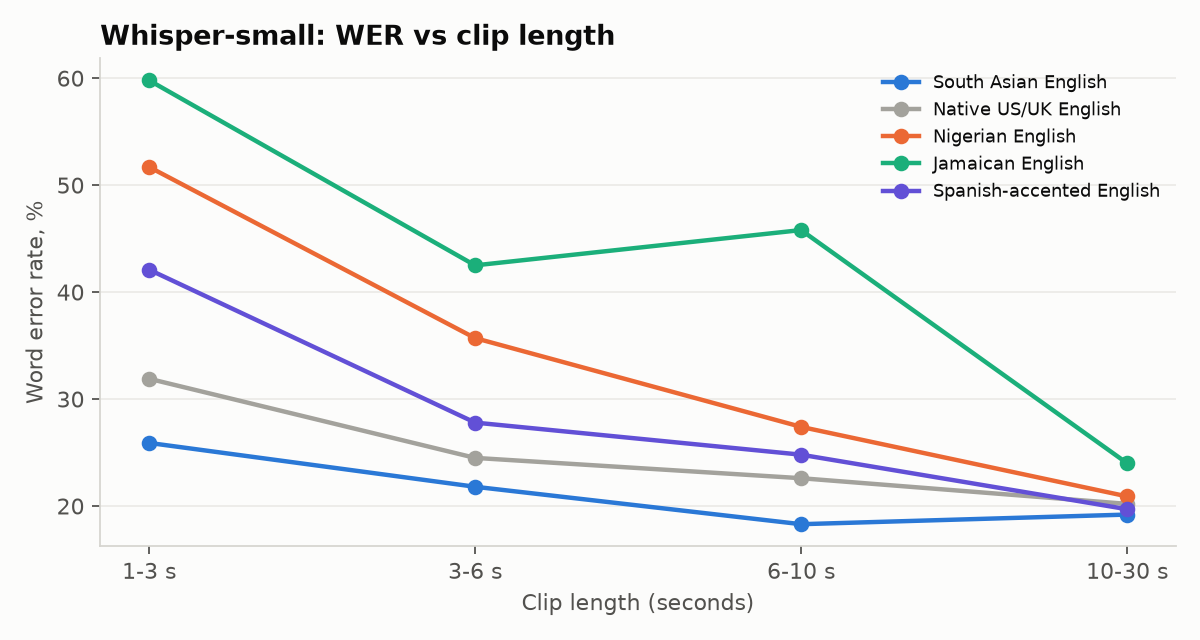

In [15]:
show("wer_by_length.csv"); display(Image(R + "wer_by_length.png"))

Inserted words (hallucination check): does prompting make Whisper invent words?

In [16]:
ins = pd.read_csv(R + "insertions_by_system.csv")
ins.pivot_table(index="group", columns="system", values="insertion_rate_pct")

system,base_personal_v1,base_plain,medium_plain,small_control,small_control_v1,small_personal,small_personal_v1,small_plain
group,,,,,,,,
Jamaican English,24.4,16.9,3.9,8.4,28.3,5.2,21.9,8.1
Native US/UK English,8.6,4.5,1.6,1.8,4.6,1.8,5.2,1.7
Nigerian English,18.7,5.2,1.7,2.3,2.2,2.5,5.1,2.0
South Asian English,7.6,4.1,1.4,1.8,1.8,1.9,5.1,1.6
Spanish-accented English,17.6,16.1,4.6,3.0,4.3,2.8,9.6,3.0


Worst clips per group, side by side (reference vs standard vs personal mode):

In [17]:
w = pd.read_csv(R + "worst_examples.csv", keep_default_na=False)
w[["group", "speaker", "reference", "whisper_small", "personal_mode", "wer_plain", "wer_personal", "why_we_think_it_failed"]]

,group,speaker,reference,whisper_small,personal_mode,wer_plain,wer_personal,why_we_think_it_failed
0,Jamaican English,EDACC-C52-B,LIKE I KNOW I WATCH UM UH UH I,"But I know I watch um, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I, I,...","But I know I watch, um, TriX, the, uh, Ice",1616.7,66.7,
1,Jamaican English,EDACC-C52-B,BECAUSE EVEN WHEN YOU PLAY,"Muka, if you wanna play Shift and See",Muka even a play a shift fan fee.,160.0,140.0,
2,Jamaican English,EDACC-C52-B,YEAH MUCH FINI UH FINISH OFF WATCHING ALL SEASON,"Yeah, I'm not sure if you know what I'm saying.","Yeah, much, I feel no, finish up, watch out, I'll see you soon.",137.5,137.5,
3,Jamaican English,EDACC-C52-B,ME PREFERS NARUTO MORE THAN DRAGON BALL Z,I prefer to know what's off with my underground boundary.,"I prefer to know what's off, with my android and battery.",137.5,150.0,Jamaican English: 'me prefers Naruto more than Dragon Ball Z' became 'I prefer to know what's off with my underground boundary'. Two problems at once: rare names (anime titles) and Jamaican Creole...
4,Jamaican English,EDACC-C52-B,NO NEVER WATCH UMBRELLA ACADEMY BEFORE,"No, no watch I'm gonna open them for","No, no watch, I'm gonna open them full.",133.3,133.3,
5,Jamaican English,EDACC-C49-B,IT'S A HA YEAH LITERALLY,"Yeah, I'm totally","yeah, i'm totally",100.0,100.0,
6,Jamaican English,EDACC-C49-B,I DON'T REALLY EAT PIZZA THAT,Are you?,Are you?,100.0,100.0,
7,Jamaican English,EDACC-C49-B,MY FAVORITE IS THE CH CHEESE THOUGH OH MY GOD,"So, um","mexico,",100.0,100.0,
8,Jamaican English,EDACC-C49-B,THE CHEESE IS BOMB AS HELL,You can use the files too.,"music, why also?",100.0,100.0,
9,Jamaican English,EDACC-C49-B,PROBABLY I AM I PROBABLY AM,No problem.,No problem.,100.0,100.0,
